Imports

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 36
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

IMG_SIZE = (150, 150)
BATCH_SIZE = 100
EPOCHS = 15

Téléchargement du dataset

On récupère un dataset public venant de kaggle : https://www.kaggle.com/datasets/princelv84/dogsvscats/data

In [73]:
import shutil
import time
from pathlib import Path
from typing import Dict, Tuple
import kagglehub

DATASET_ID = "princelv84/dogsvscats"
OUTPUT_DIR = Path("data/cats_and_dogs_filtered")
QUOTA = {"train": 3000, "validation": 500}
IMG_EXT = (".jpg", ".jpeg", ".png")


def _log(message: str) -> None:
    print(f"\033[1;34m[\033[0;36mLoading\033[1;34m]\033[0m {message}\033[0m")


def _count(folder: Path) -> Dict[str, int]:
    return {
        c: len([f for f in (folder / c).glob("*") if f.suffix.lower() in IMG_EXT])
        for c in ("cats", "dogs")
    }


def download_and_prepare_dataset(
    output_dir: Path | str = OUTPUT_DIR,
    dataset_id: str = DATASET_ID,
    quota: Dict[str, int] = QUOTA,
    seed: int = SEED,
) -> Tuple[str, str]:
    start = time.time()
    output_dir = Path(output_dir)
    train_dir, val_dir = output_dir / "train", output_dir / "validation"

    if all(_count(d) == {"cats": quota[n], "dogs": quota[n]}
           for d, n in ((train_dir, "train"), (val_dir, "validation"))):
        _log("\033[1;32mDataset already prepared, skipping.")
        return str(train_dir), str(val_dir)

    _log(f"\033[1;33mDownloading dataset '{dataset_id}' via kagglehub...")
    try:
        download_path = Path(kagglehub.dataset_download(dataset_id))
    except Exception as exc:
        raise RuntimeError("[Dataloader] Unable to download dataset via kagglehub.") from exc
    _log(f"Downloaded to {download_path}")

    source = download_path / "train"
    if not source.exists():
        raise FileNotFoundError(f"[Dataloader] No 'train' folder found in {download_path}")

    shutil.rmtree(output_dir, ignore_errors=True)

    random.seed(seed)
    needed = sum(quota.values())
    for cls in ("cats", "dogs"):
        files = sorted(f for f in (source / cls).glob("*") if f.suffix.lower() in IMG_EXT)
        _log(f"Found {len(files)} {cls} in the source train folder.")
        if len(files) < needed:
            raise FileNotFoundError(
                f"[Dataloader] Only {len(files)} '{cls}' images found, {needed} needed in {source / cls}"
            )
        random.shuffle(files)
        offset = 0
        for split, n in quota.items():
            dest = output_dir / split / cls
            dest.mkdir(parents=True, exist_ok=True)
            for f in files[offset:offset + n]:
                shutil.copy(f, dest / f.name)
            offset += n

    _log(f"Train: {_count(train_dir)} | Validation: {_count(val_dir)}")
    _log(f"\033[1;32mDataset ready in {time.time() - start:.2f} seconds.")
    return str(train_dir), str(val_dir)

Call the dataloader

In [74]:
train_dir, validation_dir = download_and_prepare_dataset()

[Loading] Downloading dataset 'princelv84/dogsvscats' via kagglehub...
[Loading] Downloaded to /Users/victor/.cache/kagglehub/datasets/princelv84/dogsvscats/versions/1
[Loading] Found 10000 cats in the source train folder.
[Loading] Found 10000 dogs in the source train folder.
[Loading] Train: {'cats': 3000, 'dogs': 3000} | Validation: {'cats': 500, 'dogs': 500}
[Loading] Dataset ready in 4.38 seconds.


Analyze class distribution

train      : {'cats': 3000, 'dogs': 3000} -> total 6000
validation : {'cats': 500, 'dogs': 500} -> total 1000


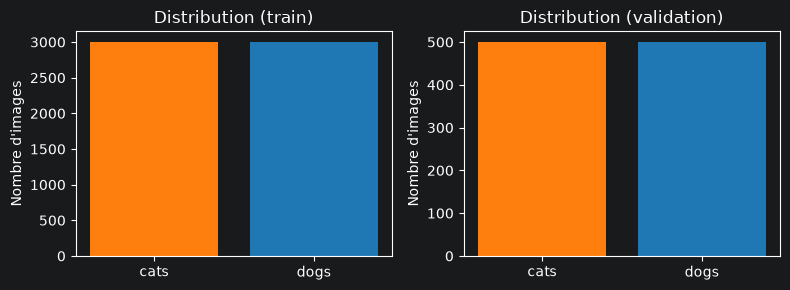

In [75]:
def list_images(folder):
    return [f for f in os.listdir(folder) if f.lower().endswith(IMG_EXT)]

counts = {
    "train": {c: len(list_images(os.path.join(train_dir, c))) for c in ["cats", "dogs"]},
    "validation": {c: len(list_images(os.path.join(validation_dir, c))) for c in ["cats", "dogs"]},
}
for split, c in counts.items():
    print(f"{split:<11}: {c} -> total {sum(c.values())}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (split, c) in zip(axes, counts.items()):
    ax.bar(c.keys(), c.values(), color=["tab:orange", "tab:blue"])
    ax.set_title(f"Distribution ({split})")
    ax.set_ylabel("Nombre d'images")
plt.tight_layout()
plt.show()

Visualization

Largeur : min 50, max 500, médiane 408
Hauteur : min 49, max 500, médiane 374
Shape d'entrée choisie : (150, 150, 3)


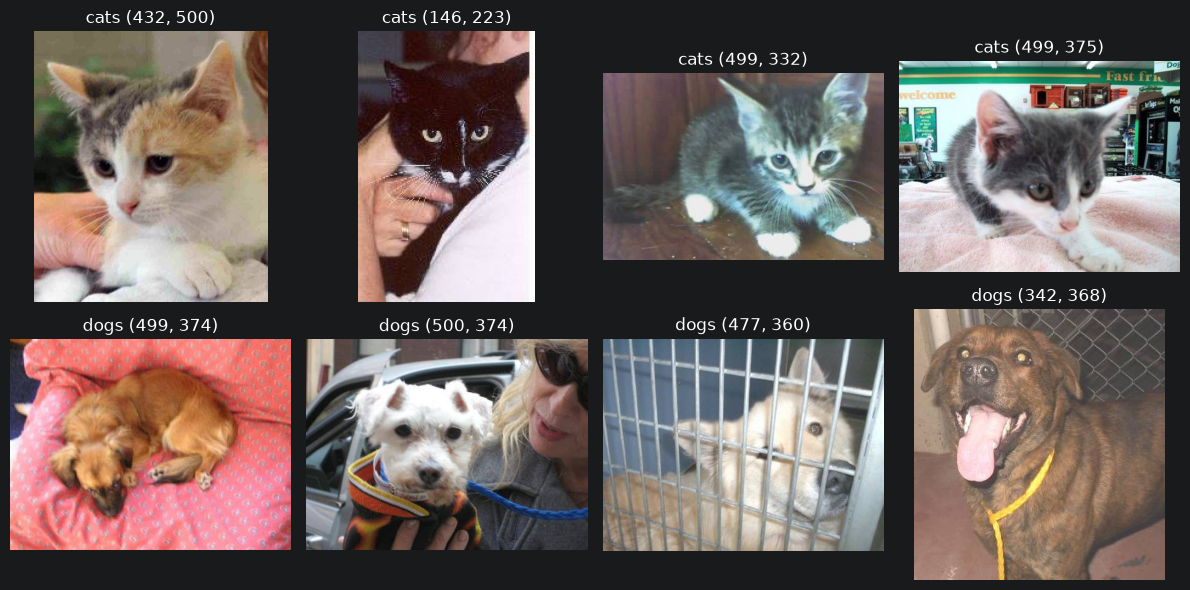

In [76]:
sizes = []
for cls in ["cats", "dogs"]:
    folder = os.path.join(train_dir, cls)
    for f in random.sample(list_images(folder), 200):
        sizes.append(Image.open(os.path.join(folder, f)).size)
widths, heights = zip(*sizes)
print(f"Largeur : min {min(widths)}, max {max(widths)}, médiane {int(np.median(widths))}")
print(f"Hauteur : min {min(heights)}, max {max(heights)}, médiane {int(np.median(heights))}")
print(f"Shape d'entrée choisie : {IMG_SIZE + (3,)}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, cls in enumerate(["cats", "dogs"]):
    folder = os.path.join(train_dir, cls)
    for col, f in enumerate(random.sample(list_images(folder), 4)):
        img = Image.open(os.path.join(folder, f))
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{cls} {img.size}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

On a choisi 150x150 de manière arbitraire. Les images n'ont pas toutes la même taille sauf qu'un réseau a besoin d'entrées de taille fixe. Les images sont proches du carré donc ce format la déformera peu l'image. En 150x150 on peut toujours distinguer les éléments principaux sachant que cela nous permet de garder un coût de calcul raisonnable sur le CPU. En 150x150 ça nous fait 22500 pixels et donc on obtiendra environ 3M de paramètres alors que si on prend la médiane ou alors juste 224x224 alors le nombre de paramètres passerait à environ 9M.

Build dataset

In [77]:
def build_dataframe(folder):
    rows = [
        {"path": os.path.join(folder, cls, f), "label": cls}
        for cls in ["cats", "dogs"]
        for f in list_images(os.path.join(folder, cls))
    ]
    return pd.DataFrame(rows)

df_all_train = build_dataframe(train_dir)
df_val = build_dataframe(validation_dir)

df_train, df_test = train_test_split(
    df_all_train, test_size=0.2, shuffle=True,
    stratify=df_all_train["label"], random_state=SEED,
)
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

for name, d in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    print(f"{name:<11}: {len(d)} images -> {d['label'].value_counts().to_dict()}")

assert not set(df_train["path"]) & set(df_test["path"])
assert not set(df_train["path"]) & set(df_val["path"])
assert not set(df_test["path"]) & set(df_val["path"])
print("OK : les trois ensembles sont disjoints")

train      : 4800 images -> {'dogs': 2400, 'cats': 2400}
validation : 1000 images -> {'cats': 500, 'dogs': 500}
test       : 1200 images -> {'dogs': 600, 'cats': 600}
OK : les trois ensembles sont disjoints


Data generator



In [79]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rescale=1.0 / 255)

def make_generator(df, shuffle):
    return datagen.flow_from_dataframe(
        df, x_col="path", y_col="label",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="binary",
        classes=["cats", "dogs"],
        shuffle=shuffle,
        seed=SEED,
    )

train_gen = make_generator(df_train, shuffle=True)
val_gen = make_generator(df_val, shuffle=False)
test_gen = make_generator(df_test, shuffle=False)

print(train_gen.class_indices)
x_batch, y_batch = next(train_gen)
print("Batch :", x_batch.shape, y_batch.shape, "| min/max pixels :", x_batch.min(), x_batch.max())

Found 4800 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.
Found 1200 validated image filenames belonging to 2 classes.
{'cats': 0, 'dogs': 1}
Batch : (100, 150, 150, 3) (100,) | min/max pixels : 0.0 1.0


Step 3 : Building the model

In [85]:
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(SEED)

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])


model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_76 (Conv2D)              │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_76 (MaxPooling2D) │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_77 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_77 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_78 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_78 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_79 (Conv2D)              │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_79 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_19 (Flatten)            │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

Nous utilisons des filtres 3×3 et un nombre de filtres croissant (32, 64, 128, 128). Les premières couches détectent des motifs simples et peu variés (bords, couleurs), les couches profondes combinent ces motifs en formes plus variées (textures, parties d’animaux) : il faut donc plus de filtres en profondeur. Cette augmentation reste raisonnable car le pooling réduit la carte de 148×148 à 7×7 : le nombre de valeurs en sortie de convolution diminue (700 928, 331 776, 147 968, puis 28 800). Le dernier bloc reste à 128 filtres plutôt que 256, nous l'avions testé avec un Flatten, doubler les filtres doublerait la taille du Dense 512 (de 3,45 M à 6,81 M de paramètres au total), ce qui aggraverait le risque de mémorisation avec seulement 4 800 images. Ce choix n'est pas optimisé vu la taille de notre dataset.

Computing parameters mathematically

In [86]:
def conv_out(n, k=3, s=1, p=0):
    return (n + 2 * p - k) // s + 1

def pool_out(n, k=2, s=2):
    return (n - k) // s + 1

h, c = IMG_SIZE[0], 3
rows, total = [], 0

for f in [32, 64, 128, 128]:
    h = conv_out(h)
    params = f * (3 * 3 * c + 1)
    rows.append((f"Conv {f} filtres", f"{h}x{h}x{f}", f"{f} x (9x{c} + 1) = {params:,}"))
    total += params
    c = f
    h = pool_out(h)
    rows.append(("MaxPool 2x2", f"{h}x{h}x{c}", "0"))

flat = h * h * c
d1 = (flat + 1) * 512
d2 = (512 + 1) * 1
rows.append(("Flatten", f"{flat}", "0"))
rows.append(("Dense 512", "512", f"({flat} + 1) x 512 = {d1:,}"))
rows.append(("Dense 1 (sigmoid)", "1", f"(512 + 1) x 1 = {d2:,}"))
total += d1 + d2

print(f"{'Couche':<20}{'Sortie':<14}Paramètres")
for r in rows:
    print(f"{r[0]:<20}{r[1]:<14}{r[2]}")
print(f"\nTotal calculé : {total:,} | model.count_params() : {model.count_params():,}")
assert total == model.count_params()

Couche              Sortie        Paramètres
Conv 32 filtres     148x148x32    32 x (9x3 + 1) = 896
MaxPool 2x2         74x74x32      0
Conv 64 filtres     72x72x64      64 x (9x32 + 1) = 18,496
MaxPool 2x2         36x36x64      0
Conv 128 filtres    34x34x128     128 x (9x64 + 1) = 73,856
MaxPool 2x2         17x17x128     0
Conv 128 filtres    15x15x128     128 x (9x128 + 1) = 147,584
MaxPool 2x2         7x7x128       0
Flatten             6272          0
Dense 512           512           (6272 + 1) x 512 = 3,211,776
Dense 1 (sigmoid)   1             (512 + 1) x 1 = 513

Total calculé : 3,453,121 | model.count_params() : 3,453,121


Step 4 : Training the model

In [87]:
train_gen = make_generator(df_train, shuffle=True)

history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True)],
)

Found 4800 validated image filenames belonging to 2 classes.
Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 43s 883ms/step - accuracy: 0.5231 - loss: 0.7145 - val_accuracy: 0.6160 - val_loss: 0.6688
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 46s 952ms/step - accuracy: 0.5908 - loss: 0.6657 - val_accuracy: 0.6100 - val_loss: 0.6464
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.6565 - loss: 0.6139 - val_accuracy: 0.6670 - val_loss: 0.6090
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.6812 - loss: 0.5879 - val_accuracy: 0.6740 - val_loss: 0.5947
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.7210 - loss: 0.5479 - val_accuracy: 0.7270 - val_loss: 0.5479
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.7323 - loss: 0.5250 - val_accuracy: 0.7080 - val_loss: 0.5607
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.7442 - loss: 0.5107 - val_accuracy: 0.7600 - val_loss: 0.5060
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step -

Visualization

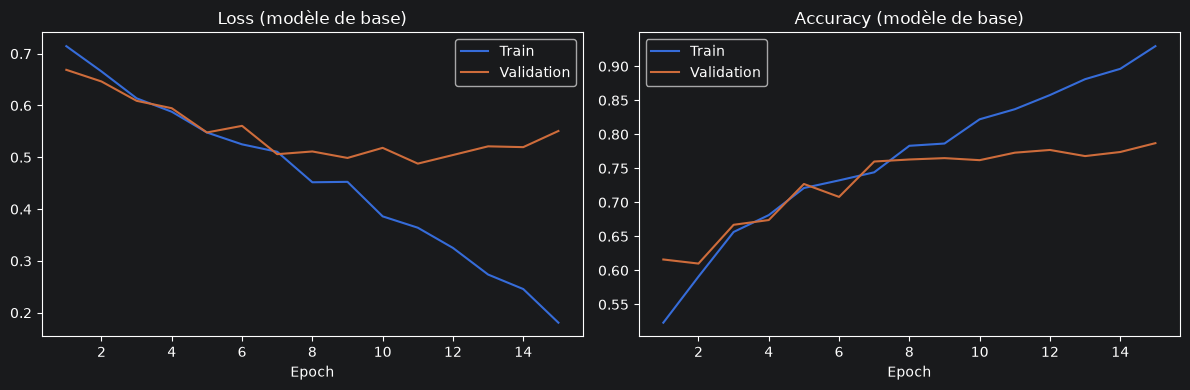

Dernière epoch -> train acc : 0.930 | val acc : 0.787
                  train loss: 0.181 | val loss: 0.551
Meilleure val acc : 0.787 (epoch 15)


In [89]:
def plot_history(history, title=""):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, h["loss"], label="Train")
    axes[0].plot(epochs, h["val_loss"], label="Validation")
    axes[0].set_title(f"Loss {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs, h["accuracy"], label="Train")
    axes[1].plot(epochs, h["val_accuracy"], label="Validation")
    axes[1].set_title(f"Accuracy {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print(f"Dernière epoch -> train acc : {h['accuracy'][-1]:.3f} | val acc : {h['val_accuracy'][-1]:.3f}")
    print(f"                  train loss: {h['loss'][-1]:.3f} | val loss: {h['val_loss'][-1]:.3f}")
    print(f"Meilleure val acc : {max(h['val_accuracy']):.3f} (epoch {int(np.argmax(h['val_accuracy'])) + 1})")

history_base = history
plot_history(history_base, "(modèle de base)")

À la dernière epoch, le modèle atteint 0,930 d’accuracy sur le train contre 0,787 sur la validation, et une loss de 0,181 contre 0,551. Cet écart (0,14 point d’accuracy, loss de validation environ 3 fois plus haute) montre un overfitting : le modèle mémorise les 4 800 images d’entraînement au lieu d’apprendre des traits qui se généralisent. Ce n’est pas de l’underfitting, puisque la performance sur le train est élevée. La cause principale est le nombre de paramètres (3,45 M, dont 93 % dans le Dense après le Flatten) par rapport à la taille du jeu d’entraînement, sans aucune régularisation à ce stade (ni Dropout, ni BatchNorm, ni augmentation)

Save the model

In [91]:
os.makedirs("models", exist_ok=True)
model.save("models/cnn_base.keras")

Step 5 : Evaluate the model on the test set

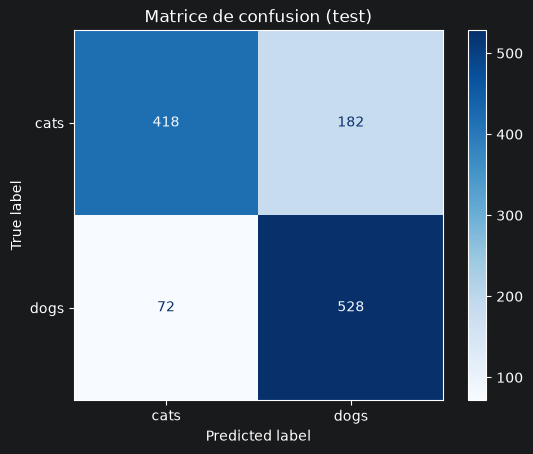

TN=418  FP=182  FN=72  TP=528


In [92]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

def predict_on(model, gen, threshold=0.5):
    gen.reset()
    proba = model.predict(gen, verbose=0).ravel()
    pred = (proba > threshold).astype(int)
    return gen.classes, pred, proba

y_true, y_pred, y_proba = predict_on(model, test_gen)

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["cats", "dogs"]).plot(cmap="Blues")
plt.title("Matrice de confusion (test)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

Metrics

In [94]:
accuracy  = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall    = tp / (tp + fn)
f1        = 2 * precision * recall / (precision + recall)

print(f"Accuracy  : {accuracy:.3f}   = (TP+TN) / total")
print(f"Precision : {precision:.3f}   = TP / (TP+FP)")
print(f"Recall    : {recall:.3f}   = TP / (TP+FN)")
print(f"F1-score  : {f1:.3f}   = 2PR / (P+R)")

assert abs(accuracy - accuracy_score(y_true, y_pred)) < 1e-9
assert abs(precision - precision_score(y_true, y_pred)) < 1e-9
assert abs(recall - recall_score(y_true, y_pred)) < 1e-9
assert abs(f1 - f1_score(y_true, y_pred)) < 1e-9

print()
print(classification_report(y_true, y_pred, target_names=["cats", "dogs"]))

for name, gen in [("train", train_gen), ("validation", val_gen), ("test", test_gen)]:
    loss, acc = model.evaluate(gen, verbose=0)
    print(f"{name:<11}: loss {loss:.3f} | accuracy {acc:.3f}")

Accuracy  : 0.788   = (TP+TN) / total
Precision : 0.744   = TP / (TP+FP)
Recall    : 0.880   = TP / (TP+FN)
F1-score  : 0.806   = 2PR / (P+R)

              precision    recall  f1-score   support

        cats       0.85      0.70      0.77       600
        dogs       0.74      0.88      0.81       600

    accuracy                           0.79      1200
   macro avg       0.80      0.79      0.79      1200
weighted avg       0.80      0.79      0.79      1200

train      : loss 0.342 | accuracy 0.852
validation : loss 0.488 | accuracy 0.773
test       : loss 0.470 | accuracy 0.788


Fonction métriques

In [95]:
results = []

def test_metrics(m, name):
    y_true, y_pred, _ = predict_on(m, test_gen)
    row = {
        "modèle": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }
    results[:] = [r for r in results if r["modèle"] != name]
    results.append(row)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})
    return row

test_metrics(model, "CNN de base")

{'modèle': 'CNN de base', 'accuracy': 0.788, 'precision': 0.744, 'recall': 0.88, 'f1': 0.806}


{'modèle': 'CNN de base',
 'accuracy': 0.7883333333333333,
 'precision': 0.7436619718309859,
 'recall': 0.88,
 'f1': 0.8061068702290076}

Bad classifications images

254 erreurs sur 1200 images


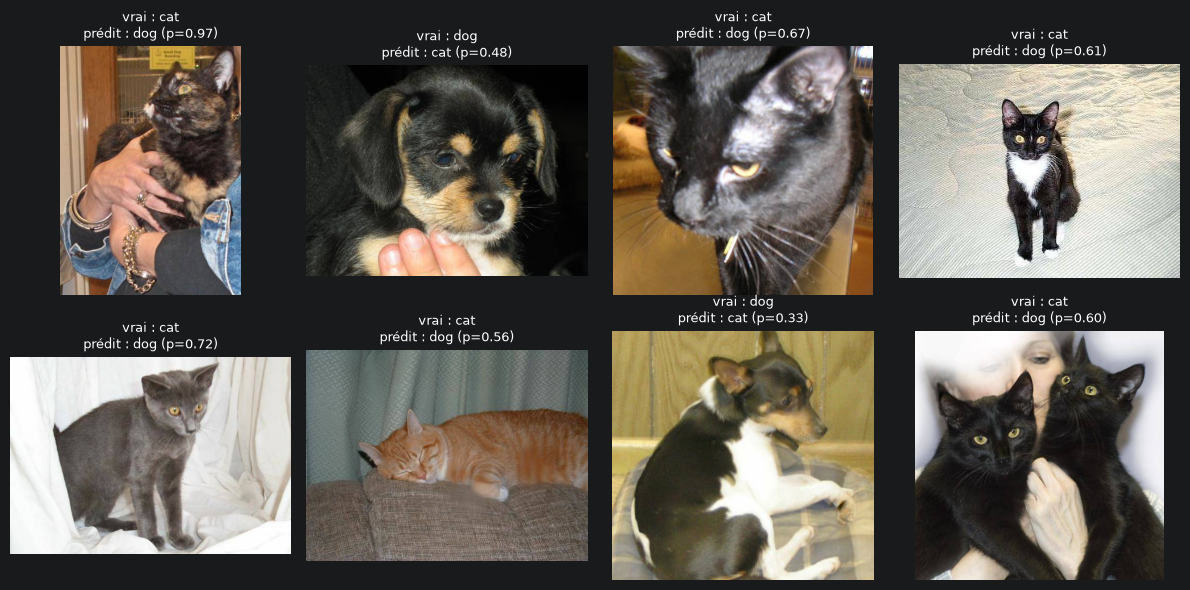

In [96]:
errors = np.where(y_pred != y_true)[0]
print(f"{len(errors)} erreurs sur {len(y_true)} images")

names = ["cat", "dog"]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, idx in zip(axes.ravel(), errors[:8]):
    img = Image.open(test_gen.filepaths[idx])
    ax.imshow(img)
    ax.set_title(f"vrai : {names[y_true[idx]]}\nprédit : {names[y_pred[idx]]} (p={y_proba[idx]:.2f})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Data augmentation

In [97]:
aug_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
)

def make_aug_generator(df, shuffle):
    return aug_datagen.flow_from_dataframe(
        df, x_col="path", y_col="label",
        target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="binary", classes=["cats", "dogs"],
        shuffle=shuffle, seed=SEED,
    )


Data augmentation example

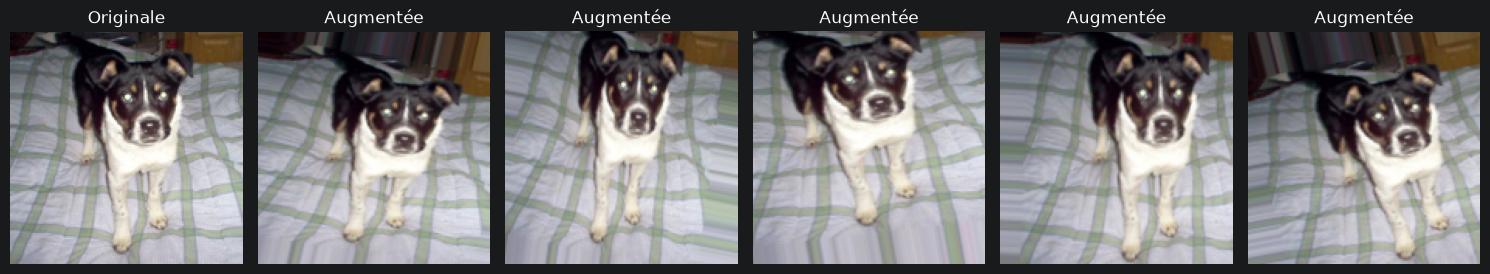

In [98]:
img = np.array(Image.open(df_train["path"][0]).convert("RGB").resize(IMG_SIZE)) / 255.0

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img)
axes[0].set_title("Originale")
for ax in axes[1:]:
    ax.imshow(np.clip(aug_datagen.random_transform(img), 0, 1))
    ax.set_title("Augmentée")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Training the data augmented

Found 4800 validated image filenames belonging to 2 classes.
Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.5181 - loss: 0.7185 - val_accuracy: 0.5940 - val_loss: 0.6780
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.5810 - loss: 0.6710 - val_accuracy: 0.6170 - val_loss: 0.6442
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.6375 - loss: 0.6334 - val_accuracy: 0.6740 - val_loss: 0.5893
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.6475 - loss: 0.6269 - val_accuracy: 0.6950 - val_loss: 0.6127
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.6829 - loss: 0.5892 - val_accuracy: 0.7500 - val_loss: 0.5405
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.6752 - loss: 0.6058 - val_accuracy: 0.7390 - val_loss: 0.5504
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.7119 - loss: 0.5589 - val_accuracy: 0.7360 - val_loss: 0.5393
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accur

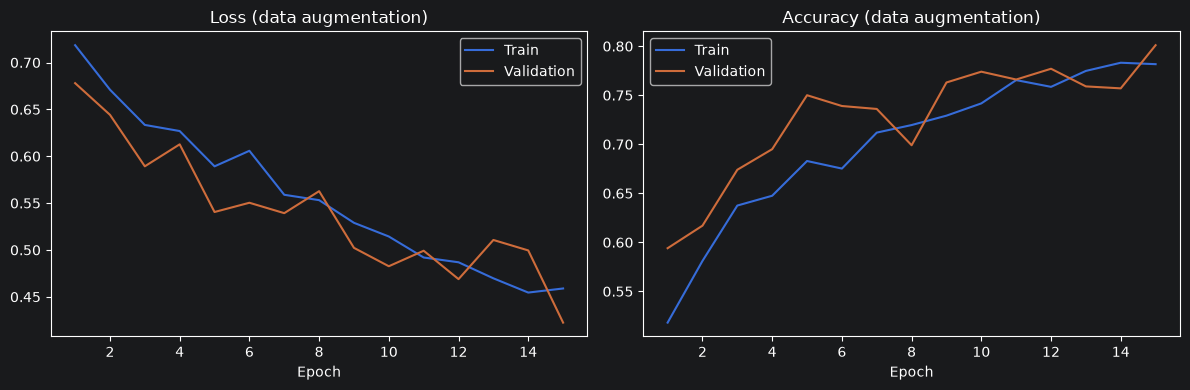

Dernière epoch -> train acc : 0.782 | val acc : 0.801
                  train loss: 0.459 | val loss: 0.422
Meilleure val acc : 0.801 (epoch 15)
{'modèle': 'CNN + augmentation', 'accuracy': 0.8, 'precision': 0.774, 'recall': 0.848, 'f1': 0.809}


{'modèle': 'CNN + augmentation',
 'accuracy': 0.8,
 'precision': 0.7735562310030395,
 'recall': 0.8483333333333334,
 'f1': 0.809220985691574}

In [99]:
tf.keras.utils.set_random_seed(SEED)
model_aug = tf.keras.models.clone_model(model)
model_aug.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

train_gen_aug = make_aug_generator(df_train, shuffle=True)
history_aug = model_aug.fit(
    train_gen_aug,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True)],
)

plot_history(history_aug, "(data augmentation)")
model_aug.save("models/cnn_augmentation.keras")
test_metrics(model_aug, "CNN + augmentation")

Avec l’augmentation, l’écart entre train et validation disparaît : 0,782 contre 0,801 d’accuracy, et 0,459 contre 0,422 de loss. On a plus d'overfitting. Le modèle ne peut plus mémoriser les images d’entraînement, car elles changent à chaque epoch (rotations, décalages, zooms, retournements). Sur le test, il atteint 0,800 d’accuracy, avec une precision de 0,774, un recall de 0,848 et un F1 de 0,809. Le modèle détecte bien les chiens (recall élevé) mais les prédit un peu trop souvent : environ 149 faux positifs contre 91 faux négatifs, d’après les valeurs de la precision et du recall.

Dropout layer and Batch normalisation

In [100]:
tf.keras.utils.set_random_seed(SEED)

model_reg = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

model_reg.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_reg.summary()

Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_80 (Conv2D)              │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 148, 148, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_80 (MaxPooling2D) │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_81 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_57          │ (None, 72, 72, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_81 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_82 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_58          │ (None, 34, 34, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_82 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_83 (Conv2D)              │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_59          │ (None, 15, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_83 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 512)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 308,801 (1.18 MB)

 Trainable params: 308,097 (1.18 MB)

 Non-trainable params: 704 (2.75 KB)

In [101]:
canaux = [3, 32, 64, 128, 128]
conv_params = sum(f * (9 * c + 1) for c, f in zip(canaux[:-1], canaux[1:]))
bn_params = sum(4 * f for f in canaux[1:])
dense_params = (128 + 1) * 512 + (512 + 1) * 1

total = conv_params + bn_params + dense_params
print(f"Convolutions : {conv_params:,}")
print(f"BatchNorm    : {bn_params:,} (dont {bn_params // 2} non entraînables)")
print(f"Dense        : {dense_params:,}")
print(f"Total        : {total:,} | model_reg.count_params() : {model_reg.count_params():,}")
assert total == model_reg.count_params()

Convolutions : 240,832
BatchNorm    : 1,408 (dont 704 non entraînables)
Dense        : 66,561
Total        : 308,801 | model_reg.count_params() : 308,801


Le modèle avec BatchNorm, GlobalAveragePooling et Dropout compte 308 801 paramètres, soit environ 11 fois moins que le modèle de base (3 453 121). Cette réduction vient entièrement du remplacement du Flatten par un GlobalAveragePooling : le Dense reçoit 128 valeurs au lieu de 6 272, ce qui fait passer cette couche de 3 211 776 à 66 048 paramètres (hors sortie). Les convolutions restent identiques (240 832). La BatchNorm n’ajoute que 1 408 paramètres, dont 704 non entraînables, et le Dropout n’en ajoute aucun.

Train after batch normalization and dropout

Found 4800 validated image filenames belonging to 2 classes.
Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.6090 - loss: 0.6766 - val_accuracy: 0.6000 - val_loss: 0.6937
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.6781 - loss: 0.5982 - val_accuracy: 0.7220 - val_loss: 0.5692
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.7233 - loss: 0.5571 - val_accuracy: 0.7440 - val_loss: 0.5364
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.7390 - loss: 0.5279 - val_accuracy: 0.7310 - val_loss: 0.5364
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.7615 - loss: 0.4961 - val_accuracy: 0.7450 - val_loss: 0.5338
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.7812 - loss: 0.4731 - val_accuracy: 0.7490 - val_loss: 0.5076
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.7948 - loss: 0.4394 - val_accuracy: 0.7660 - val_loss: 0.4849
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accur

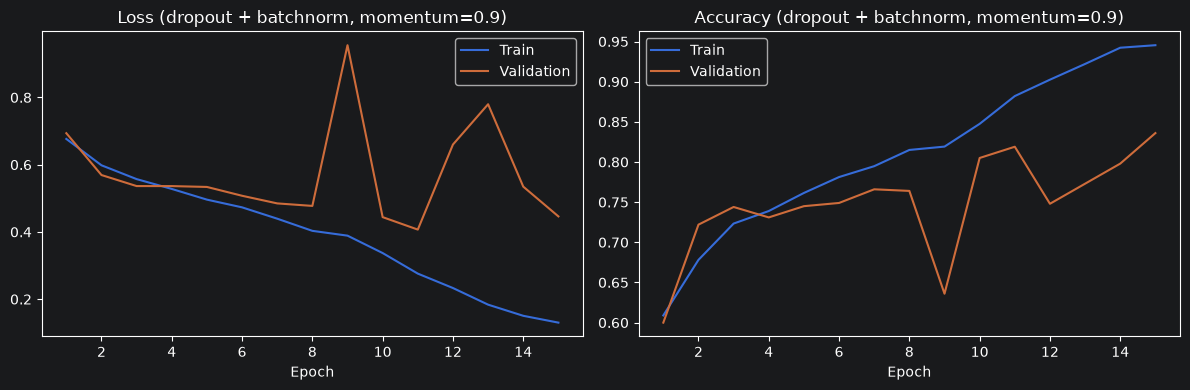

Dernière epoch -> train acc : 0.945 | val acc : 0.836
                  train loss: 0.130 | val loss: 0.446
Meilleure val acc : 0.836 (epoch 15)
{'modèle': 'CNN + dropout + BN', 'accuracy': 0.836, 'precision': 0.852, 'recall': 0.813, 'f1': 0.832}


In [102]:
train_gen = make_generator(df_train, shuffle=True)
history_reg = model_reg.fit(train_gen, epochs=EPOCHS, validation_data=val_gen, callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True)],)

plot_history(history_reg, "(dropout + batchnorm, momentum=0.9)")
model_reg.save("models/cnn_dropout_bn.keras")
test_metrics(model_reg, "CNN + dropout + BN");

Le modèle avec BatchNorm, GlobalAveragePooling et Dropout (0,5) atteint 0,945 d’accuracy sur le train et 0,836 sur la validation (loss 0,130 contre 0,446). Sur le test, il obtient 0,836 d’accuracy, une precision de 0,852, un recall de 0,813 et un F1 de 0,832. Par rapport au modèle de base (0,930 contre 0,787 en train/validation), la validation progresse et l’écart d’accuracy se réduit (0,11 contre 0,14). Mais l’overfitting persiste : la loss de validation reste environ 3,4 fois supérieure à celle du train, et la meilleure val accuracy est atteinte à la dernière epoch, ce qui suggère que le modèle progresse encore. La BatchNorm stabilise et accélère l’apprentissage. Le Dropout limite la co-adaptation des neurones de la couche Dense, mais seul, il ne supprime pas la mémorisation. Il faut aussi nuancer : ce modèle remplace le Flatten par un GlobalAveragePooling, ce qui réduit les paramètres de 3,45 M à 308 801. Une partie du gain vient donc de cette réduction et non de la BatchNorm ou du Dropout seuls.

Ainsi la solution serait d'implémenter les deux solutions en une, le batchNorm avec dropout et le data augmentation

Comparing the dropout

In [24]:
def show(p, h):
    print(f"dropout={p} | val acc max {max(h.history['val_accuracy']):.3f} | "
          f"val loss min {min(h.history['val_loss']):.3f}")

for p in [0.3, 0.7]:
    tf.keras.utils.set_random_seed(SEED)

    m = models.Sequential([layers.Input(shape=IMG_SIZE + (3,))])
    for f in [32, 64, 128, 128]:
        m.add(layers.Conv2D(f, (3, 3), activation="relu"))
        m.add(layers.BatchNormalization(momentum=0.9))
        m.add(layers.MaxPooling2D((2, 2)))
    m.add(layers.GlobalAveragePooling2D())
    m.add(layers.Dense(512, activation="relu"))
    m.add(layers.Dropout(p))
    m.add(layers.Dense(1, activation="sigmoid"))

    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    train_gen = make_generator(df_train, shuffle=True)
    h = m.fit(train_gen, epochs=EPOCHS, validation_data=val_gen, verbose=0)
    show(p, h)

show(0.5, history_reg)

Found 4800 validated image filenames belonging to 2 classes.
dropout=0.3 | val acc max 0.828 | val loss min 0.390
Found 4800 validated image filenames belonging to 2 classes.
dropout=0.7 | val acc max 0.828 | val loss min 0.376
dropout=0.5 | val acc max 0.845 | val loss min 0.360


Selon la comparaison 0.5 comme valeur de taux de dropout reste la plus pertinente.

Creating the model with the best dropout

In [103]:
best_dropout = 0.5

tf.keras.utils.set_random_seed(SEED)
model_full = models.Sequential([layers.Input(shape=IMG_SIZE + (3,))])
for f in [32, 64, 128, 128]:
    model_full.add(layers.Conv2D(f, (3, 3), activation="relu"))
    model_full.add(layers.BatchNormalization(momentum=0.9))
    model_full.add(layers.MaxPooling2D((2, 2)))
model_full.add(layers.GlobalAveragePooling2D())
model_full.add(layers.Dense(512, activation="relu"))
model_full.add(layers.Dropout(best_dropout))
model_full.add(layers.Dense(1, activation="sigmoid"))

model_full.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_full.summary()

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_84 (Conv2D)              │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_60          │ (None, 148, 148, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_84 (MaxPooling2D) │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_85 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_61          │ (None, 72, 72, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_85 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_86 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_62          │ (None, 34, 34, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_86 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_87 (Conv2D)              │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_63          │ (None, 15, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_87 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 512)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 308,801 (1.18 MB)

 Trainable params: 308,097 (1.18 MB)

 Non-trainable params: 704 (2.75 KB)

Final training

Found 4800 validated image filenames belonging to 2 classes.
Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.6525 - loss: 0.6252 - val_accuracy: 0.6970 - val_loss: 0.6000
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.6721 - loss: 0.6008 - val_accuracy: 0.7040 - val_loss: 0.5623
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.7108 - loss: 0.5649 - val_accuracy: 0.7570 - val_loss: 0.4987
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.7352 - loss: 0.5415 - val_accuracy: 0.7550 - val_loss: 0.5228
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.7492 - loss: 0.5136 - val_accuracy: 0.7680 - val_loss: 0.4949
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.7500 - loss: 0.5124 - val_accuracy: 0.6150 - val_loss: 0.8172
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.7648 - loss: 0.4921 - val_accuracy: 0.7470 - val_loss: 0.4997
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - acc

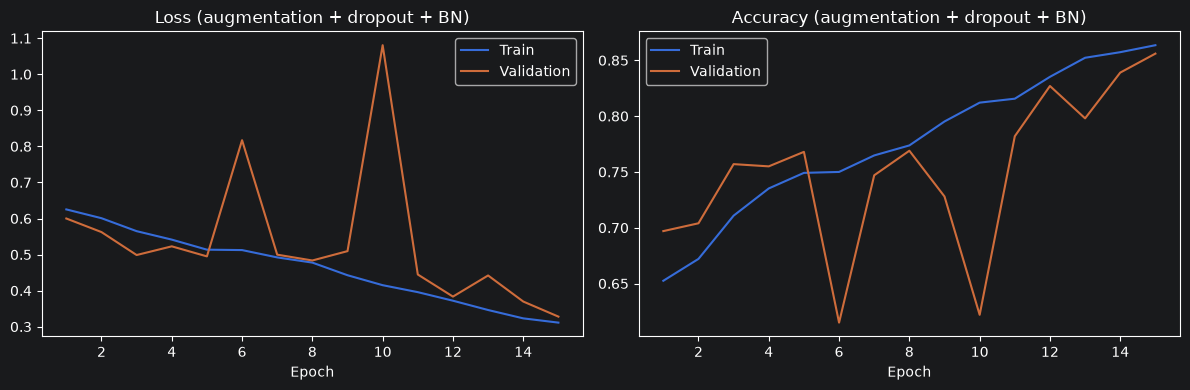

Dernière epoch -> train acc : 0.864 | val acc : 0.856
                  train loss: 0.311 | val loss: 0.328
Meilleure val acc : 0.856 (epoch 15)
{'modèle': 'CNN + aug + dropout + BN', 'accuracy': 0.871, 'precision': 0.861, 'recall': 0.885, 'f1': 0.873}


{'modèle': 'CNN + aug + dropout + BN',
 'accuracy': 0.8708333333333333,
 'precision': 0.8606158833063209,
 'recall': 0.885,
 'f1': 0.8726376335250616}

In [105]:
train_gen_aug = make_aug_generator(df_train, shuffle=True)
history_full = model_full.fit(
    train_gen_aug,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True)],
)

plot_history(history_full, "(augmentation + dropout + BN)")
model_full.save("models/cnn_full.keras")
test_metrics(model_full, "CNN + aug + dropout + BN")

Le modèle combiné ne montre aucun signe d’overfitting. À la dernière epoch, la train accuracy est de 0,864 contre 0,856 en validation (loss 0,311 contre 0,328) : l’écart est inférieur à 0,01, alors qu’il était de 0,14 pour le modèle de base et de 0,11 pour Dropout + BatchNorm seul. L’augmentation empêche la mémorisation des images, tandis que la BatchNorm compense le ralentissement qu’elle provoque. La validation atteint 0,856, la meilleure de nos CNN.

Le modèle n’a pas fini d’apprendre : sur les epochs 11 à 15, la train accuracy passe de 0,816 à 0,864 et la val loss de 0,445 à 0,328, et le meilleur point des epochs affichés est le dernier. L’early stopping ne s’est pas déclenché, et la limite de 15 epochs fixée par le sujet nous arrête avant la convergence.

On observe une instabilité à l’epoch 10 : la validation chute à 0,622 (loss 1,081) avant de remonter à 0,782 à l’epoch suivante. Elle est typique de la BatchNorm, qui utilise en validation des moyennes mobiles pouvant être décalées par rapport aux statistiques des batchs tant que l’entraînement n’a pas convergé. La train accuracy étant mesurée sur des images augmentées et avec le Dropout actif, elle sous-estime la performance réelle du modèle.

Bonus : Transfer learning avec MobileNetV2

On réutilise MobileNetV2 pré-entraîné sur ImageNet (1,4 M d'images, 1000 classes) comme extracteur de features.
Ses couches convolutives sont gelées : seule la tête de classification (GlobalAveragePooling + Dense sigmoid) est entraînée.
MobileNetV2 attend des pixels dans [-1, 1], d'où la couche Rescaling (nos générateurs donnent [0, 1]).

In [106]:
tf.keras.utils.set_random_seed(SEED)

base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

model_tl = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(2.0, offset=-1.0),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),
])

model_tl.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_tl.summary()

/var/folders/vh/zgj4_kyj07s5_1cql8bkl5qr0000gn/T/ipykernel_2008/372029991.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")


Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Entraînement de la tête de classification (5 epochs suffisent, les features sont déjà apprises)

Found 4800 validated image filenames belonging to 2 classes.
Epoch 1/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 466ms/step - accuracy: 0.8946 - loss: 0.2412 - val_accuracy: 0.9580 - val_loss: 0.1164
Epoch 2/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 426ms/step - accuracy: 0.9525 - loss: 0.1215 - val_accuracy: 0.9610 - val_loss: 0.0961
Epoch 3/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 19s 396ms/step - accuracy: 0.9608 - loss: 0.1020 - val_accuracy: 0.9650 - val_loss: 0.0829
Epoch 4/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 407ms/step - accuracy: 0.9683 - loss: 0.0913 - val_accuracy: 0.9650 - val_loss: 0.0783
Epoch 5/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 424ms/step - accuracy: 0.9675 - loss: 0.0833 - val_accuracy: 0.9720 - val_loss: 0.0764


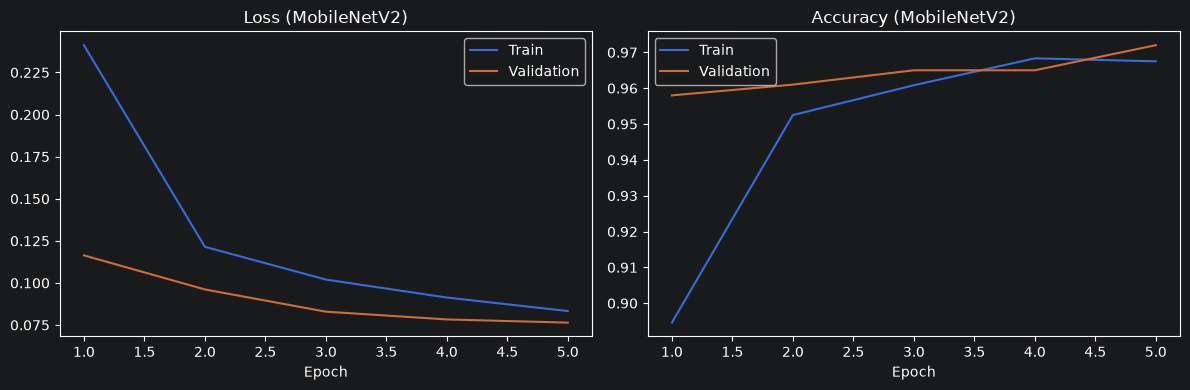

Dernière epoch -> train acc : 0.967 | val acc : 0.972
                  train loss: 0.083 | val loss: 0.076
Meilleure val acc : 0.972 (epoch 5)
{'modèle': 'MobileNetV2 (transfer learning)', 'accuracy': 0.973, 'precision': 0.967, 'recall': 0.98, 'f1': 0.974}


In [108]:
train_gen = make_generator(df_train, shuffle=True)
history_tl = model_tl.fit(train_gen, epochs=5, validation_data=val_gen)

plot_history(history_tl, "(MobileNetV2)")
model_tl.save("models/mobilenetv2.keras")
test_metrics(model_tl, "MobileNetV2 (transfer learning)");

Comparaison des modèles sur le test set

In [111]:
df_results = pd.DataFrame(results).set_index("modèle").round(3)
df_results

,accuracy,precision,recall,f1
modèle,,,,
CNN de base,0.788,0.744,0.880,0.806
CNN + augmentation,0.800,0.774,0.848,0.809
CNN + dropout + BN,0.836,0.852,0.813,0.832
CNN + aug + dropout + BN,0.871,0.861,0.885,0.873
MobileNetV2 (transfer learning),0.973,0.967,0.980,0.974


Comparaison des courbes de validation

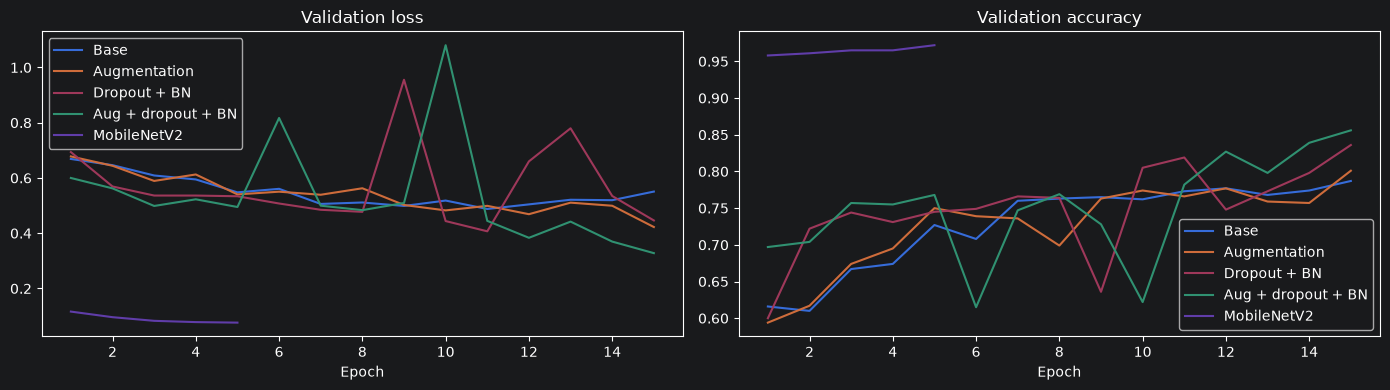

In [110]:
histories = {
    "Base": history_base,
    "Augmentation": history_aug,
    "Dropout + BN": history_reg,
    "Aug + dropout + BN": history_full,
    "MobileNetV2": history_tl,
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, h in histories.items():
    epochs = range(1, len(h.history["val_loss"]) + 1)
    axes[0].plot(epochs, h.history["val_loss"], label=name)
    axes[1].plot(epochs, h.history["val_accuracy"], label=name)

axes[0].set_title("Validation loss")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## Conclusion

- **Modèle de base** : il apprend mais overfitte nettement : 93 % d'accuracy sur le train contre 78,7 % en validation, avec une loss de 0,18 contre 0,55. Les 3,2 M de paramètres de la couche Dense après le Flatten lui permettent de mémoriser les 4 800 images.
- **Data augmentation** : l'écart entre train et validation disparaît (78,2 % contre 80,1 %). Le modèle ne peut plus mémoriser des images qui changent à chaque epoch. Il apprend en revanche plus lentement : sur le test, il atteint 80,0 % d'accuracy, avec une précision de 0,77, un recall de 0,85 et un F1 de 0,81.
- **Dropout + BatchNorm** : test à 83,6 % (précision 0,85, recall 0,81, F1 0,83). La BatchNorm accélère l'apprentissage, mais l'overfitting persiste (94,5 % en train contre 83,6 % en validation) : ce modèle s'entraîne sur les images originales, et le Dropout ne protège que la couche Dense. Le GlobalAveragePooling divise aussi le nombre de paramètres par 11 (de 3,45 M à 308 801), et une partie du gain vient de là, pas seulement de la BatchNorm et du Dropout.
- **Augmentation + Dropout + BN** : c'est notre meilleur CNN entraîné from scratch : 85,6 % en validation, avec un écart train/validation inférieur à 1 point (86,4 % contre 85,6 %). Les deux techniques se complètent : l'augmentation empêche la mémorisation, la BatchNorm compense le ralentissement qu'elle provoque. La validation reste instable d'une epoch à l'autre (chute à 62 % à l'epoch 10, puis retour à 78 %), ce qui est typique de la BatchNorm tant que l'entraînement n'a pas convergé. Le modèle progressait encore à l'epoch 15.
- **MobileNetV2** : le transfer learning dépasse tous les modèles entraînés from scratch en seulement 5 epochs, en n'entraînant que 1 281 paramètres. Les features apprises sur ImageNet (formes, textures, parties d'animaux) se transfèrent à notre tâche.

**Limites** : entraînement sur CPU seulement, donc 15 epochs maximum et 3 000 images par classe. Chaque résultat vient d'une seule exécution et les courbes de validation sont bruitées : avec 1 200 images de test. Le modèle Dropout + BN change à la fois la BatchNorm, le Dropout et la tête (GlobalAveragePooling), nous ne pouvons donc pas isoler l'effet de chacun. La validation n'est pas augmenté. Enfin, MobileNetV2 a été utilisé avec des images de 150×150, taille qui ne fait pas partie de celles pour lesquelles il est prévu (Keras charge les poids 224×224 par défaut).


Sources

- Dataset : *Dogs vs Cats*, Kaggle : https://www.kaggle.com/datasets/princelv84/dogsvscats/data
- Documentation Keras / TensorFlow : `ImageDataGenerator`, `Conv2D`, `BatchNormalization`, `EarlyStopping`, `keras.applications.MobileNetV2` : https://keras.io/api/
- Adam : Kingma & Ba, *Adam: A Method for Stochastic Optimization*, 2014 (arXiv:1412.6980)
- Dropout : Srivastava et al., *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*, JMLR 2014
- Batch Normalization : Ioffe & Szegedy, 2015 (arXiv:1502.03167)
- MobileNetV2 : Sandler et al., *MobileNetV2: Inverted Residuals and Linear Bottlenecks*, 2018 (arXiv:1801.04381)